#  `Analytical Base Table & Feature Engineering`

**Purpose.** Merge the 12 cleaned tables into **one row per order** and derive the features that power EDA, delivery-time regression and churn prediction.

**Stakeholder value.** Every KPI (late %, revenue, basket value, partner efficiency) is computed once, here, so City Operations, Marketing and Finance all read the same numbers.

In [1]:
import sys, warnings
sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from ingest import TABLES
from features import build_analytical_base_table, TRAFFIC_SCORE, RAIN_BINS
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', palette='deep'); IMG = Path('../images')
clean = {t: pd.read_csv(f'../data/cleaned/{t}.csv') for t in TABLES}

## 1 · Build the ABT
Joins: orders → restaurants (city, cuisine, rating) → customers → delivery partners → promotions → order-item aggregates → feedback → payments → **weather** (restaurant city + order date) → **traffic** (nearest reading on the same city-day).

*An order's city is the restaurant's city* — customer city in the source is unreliable (customers frequently live in a different city to the restaurant they order from).

In [2]:
abt = build_analytical_base_table(clean)
abt.to_csv('../data/cleaned/analytical_base_table.csv', index=False)
print(f'ABT: {abt.shape[0]:,} rows x {abt.shape[1]} columns   (orders table has {len(clean["orders"]):,} rows)')
assert len(abt) == len(clean['orders']) and abt['OrderID'].is_unique, 'join fan-out detected'
print('No join fan-out: one row per order. OK')

ABT: 20,475 rows x 87 columns   (orders table has 20,475 rows)
No join fan-out: one row per order. OK

### Join coverage
Weather and traffic exist only for a sample of city-days, so some orders cannot be matched directly. Unmatched orders use a documented fallback (city×month climatology / city×hour typical traffic) and are flagged.

In [3]:
pd.Series({'orders with a direct weather reading': abt['WeatherMatched'].mean(),
           'orders with a same-day traffic reading': abt['TrafficMatched'].mean(),
           'orders with line items': abt['has_line_items'].mean(),
           'orders with feedback': abt['AverageRating'].notna().mean(),
           'orders with a payment record': abt['PaymentStatus'].notna().mean()}).map('{:.1%}'.format).to_frame('coverage')

,coverage
orders with a direct weather reading,62.4%
orders with a same-day traffic reading,63.3%
orders with line items,100.0%
orders with feedback,68.7%
orders with a payment record,98.0%


## 2 · Engineered features (PRD section 23)
| Feature | Definition used |
|---|---|
| `PeakHour` | 1 if order hour is 12–14 (lunch) or 19–22 (dinner) |
| `WeekendOrder` | 1 if Saturday/Sunday |
| `RainImpact` | IMD daily-rainfall class 0–4 for the restaurant city on the order date |
| `TrafficScore` | Low=1, Moderate=2, High=3, Severe=4 from the nearest reading in time |
| `CustomerTenure` | Days from registration to order date, floored at 0 |
| `AverageBasketValue` | Mean `FinalAmount` per customer |
| `RestaurantPopularity` | Order-count and revenue rank within city |
| `DeliveryEfficiency` | Partner's average delivery time ÷ city average (< 1 is faster) |
| `CustomerLifetimeValue` | Cumulative realised revenue per customer up to and including this order |
| `OrderFrequency30d` | Orders per customer per 30-day window |
| `AverageRating` | Mean of customer, delivery and food rating |
| + `BasketSize`, `IsLate`, `DiscountPctOfFood`, `PartnerExperienceDays`, `IsRepeatCustomer`, `OrderBeforeRegistration` | supporting features |

All calculations are vectorised (no row loops).

In [4]:
feat = ['OrderHour', 'DayOfWeek', 'PeakHour', 'WeekendOrder', 'RainImpact', 'TrafficScore', 'CustomerTenure', 'AverageBasketValue',
        'PopularityRankByOrders', 'PopularityRankByRevenue', 'DeliveryEfficiency', 'CustomerLifetimeValue', 'OrderFrequency30d',
        'AverageRating', 'BasketSize', 'IsLate', 'DiscountPctOfFood', 'PartnerExperienceDays', 'IsRepeatCustomer']
print(f'{len(feat)} derived feature columns (PRD requires >= 10)')
abt[feat].describe().T.round(2)

19 derived feature columns (PRD requires >= 10)

,count,mean,std,min,25%,50%,75%,max
OrderHour,20475.0,14.20,5.17,0.00,11.00,14.00,19.00,23.00
DayOfWeek,20475.0,3.00,1.99,0.00,1.00,3.00,5.00,6.00
PeakHour,20475.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00
WeekendOrder,20475.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
RainImpact,20475.0,1.29,1.10,0.00,0.00,1.00,2.00,4.00
TrafficScore,20475.0,2.36,0.88,1.00,2.00,2.00,3.00,4.00
CustomerTenure,20475.0,262.93,281.57,0.00,0.00,177.00,463.00,1093.00
AverageBasketValue,20475.0,391.72,112.94,33.00,316.27,387.97,460.63,976.30
PopularityRankByOrders,20475.0,19.91,13.66,1.00,8.00,18.00,30.00,58.00
PopularityRankByRevenue,20475.0,22.39,14.12,1.00,10.00,21.00,34.00,58.00


### Sanity checks per feature

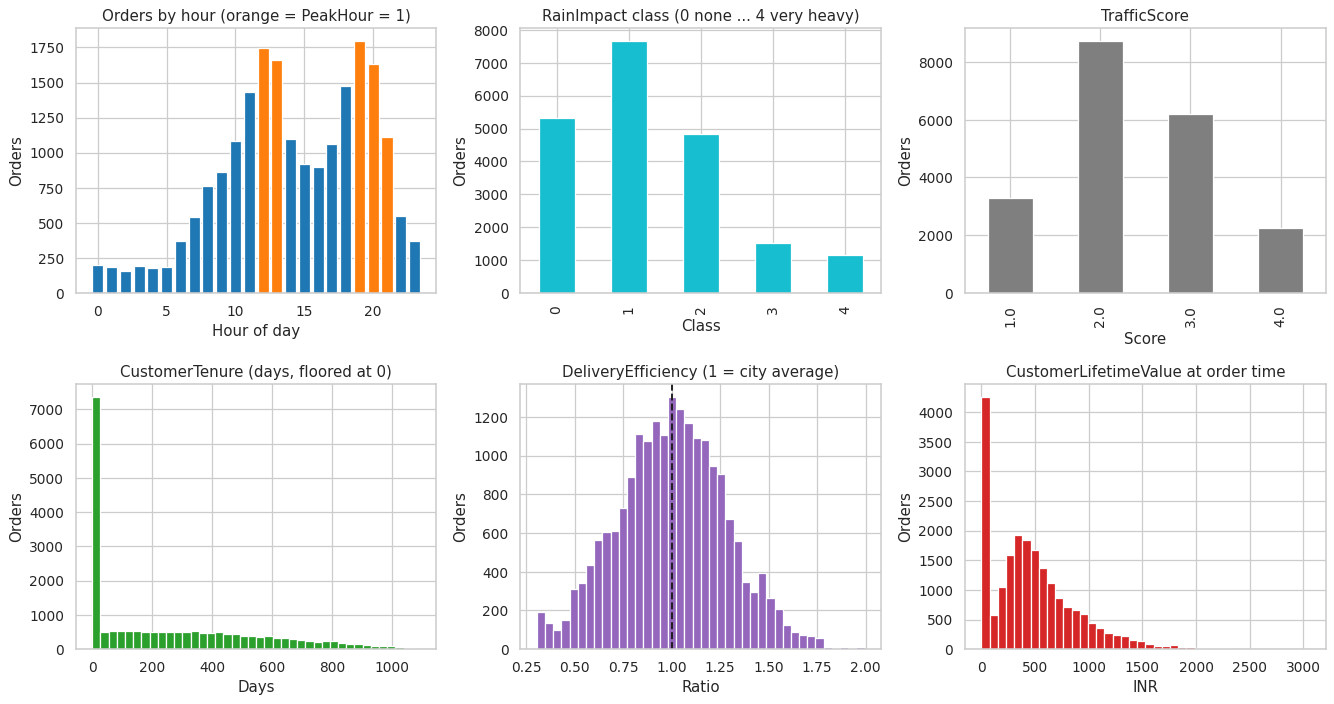

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
hourly = abt.groupby('OrderHour').size()
axes[0, 0].bar(hourly.index, hourly.values, color=np.where(hourly.index.isin([12, 13, 19, 20, 21]), 'tab:orange', 'tab:blue'))
axes[0, 0].set_title('Orders by hour (orange = PeakHour = 1)'); axes[0, 0].set_xlabel('Hour of day'); axes[0, 0].set_ylabel('Orders')
abt['RainImpact'].value_counts().sort_index().plot.bar(ax=axes[0, 1], color='tab:cyan'); axes[0, 1].set_title('RainImpact class (0 none ... 4 very heavy)'); axes[0, 1].set_xlabel('Class'); axes[0, 1].set_ylabel('Orders')
abt['TrafficScore'].round().value_counts().sort_index().plot.bar(ax=axes[0, 2], color='tab:gray'); axes[0, 2].set_title('TrafficScore'); axes[0, 2].set_xlabel('Score'); axes[0, 2].set_ylabel('Orders')
axes[1, 0].hist(abt['CustomerTenure'].dropna(), bins=40, color='tab:green'); axes[1, 0].set_title('CustomerTenure (days, floored at 0)'); axes[1, 0].set_xlabel('Days'); axes[1, 0].set_ylabel('Orders')
axes[1, 1].hist(abt['DeliveryEfficiency'], bins=40, color='tab:purple'); axes[1, 1].axvline(1, color='k', ls='--'); axes[1, 1].set_title('DeliveryEfficiency (1 = city average)'); axes[1, 1].set_xlabel('Ratio'); axes[1, 1].set_ylabel('Orders')
axes[1, 2].hist(abt['CustomerLifetimeValue'], bins=40, color='tab:red'); axes[1, 2].set_title('CustomerLifetimeValue at order time'); axes[1, 2].set_xlabel('INR'); axes[1, 2].set_ylabel('Orders')
plt.tight_layout(); plt.savefig(IMG / '03_feature_sanity.png', dpi=110)

In [6]:
checks = {
 'PeakHour share of orders': abt['PeakHour'].mean(),
 'WeekendOrder share (expected ~2/7 = 28.6%)': abt['WeekendOrder'].mean(),
 'Orders placed BEFORE customer registration': abt['OrderBeforeRegistration'].mean(),
 'Repeat-customer orders': abt['IsRepeatCustomer'].mean(),
 'Late share of delivered orders': abt.loc[abt.IsDelivered == 1, 'IsLate'].mean(),
 'Mean DeliveryEfficiency (should be ~1)': abt['DeliveryEfficiency'].mean(),
}
pd.Series(checks).round(3).to_frame('value')

,value
PeakHour share of orders,0.388
WeekendOrder share (expected ~2/7 = 28.6%),0.282
Orders placed BEFORE customer registration,0.333
Repeat-customer orders,0.819
Late share of delivered orders,0.159
Mean DeliveryEfficiency (should be ~1),1.000


> **Data-integrity finding.** About a third of orders pre-date the customer's registration date. This is a source-data inconsistency that cannot be repaired from the data; `CustomerTenure` is floored at 0 and `OrderBeforeRegistration` keeps the anomaly visible so models and dashboards can account for it.

## 3 · Does anything move delivery time? (feature screening)
Before modelling, check which engineered features relate to the target. Spearman correlation is rank-based and robust to the skew in delivery time.

Largest |correlation|: 0.017

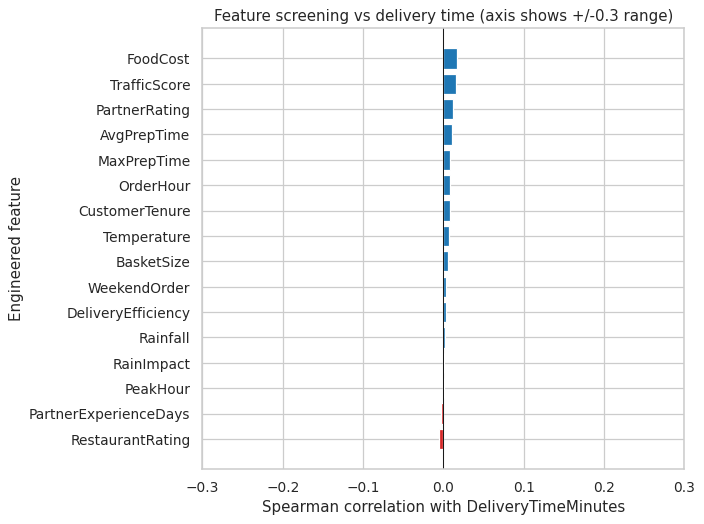

In [7]:
d = abt[(abt.IsDelivered == 1) & abt.DeliveryTimeMinutes.notna()]
cand = ['TrafficScore', 'RainImpact', 'Rainfall', 'Temperature', 'PeakHour', 'WeekendOrder', 'BasketSize', 'AvgPrepTime', 'MaxPrepTime',
        'DeliveryEfficiency', 'PartnerRating', 'PartnerExperienceDays', 'RestaurantRating', 'FoodCost', 'CustomerTenure', 'OrderHour']
corr = d[cand + ['DeliveryTimeMinutes']].corr(method='spearman')['DeliveryTimeMinutes'].drop('DeliveryTimeMinutes').sort_values()
fig, ax = plt.subplots(figsize=(8, 6)); ax.barh(corr.index, corr.values, color=np.where(corr > 0, 'tab:blue', 'tab:red'))
ax.axvline(0, color='k', lw=.8); ax.set_xlim(-.3, .3); ax.set_xlabel('Spearman correlation with DeliveryTimeMinutes'); ax.set_ylabel('Engineered feature')
ax.set_title('Feature screening vs delivery time (axis shows +/-0.3 range)'); plt.tight_layout(); plt.savefig(IMG / '03_feature_screening.png', dpi=110)
print('Largest |correlation|:', corr.abs().max().round(3))

**Important result for the modelling notebook:** no operational feature has a meaningful rank correlation with delivery time (all |ρ| < 0.03). The only strong relationship is with order *status* (`Delivered Late` orders average ~64 min vs ~34 min), which is an **outcome of** the delivery time, not a predictor available when an order is placed. Notebook 04 tests this formally.

## 4 · KPI parity: pandas vs SQL source of truth (Day 10)
Re-compute the SQL query **H7 (City scorecard)** from the ABT. After loading MySQL, run H7 and compare; the shared definitions are listed at the top of `sql/business_queries.sql`.

In [8]:
city = (abt.groupby('City').agg(orders=('OrderID', 'count'), revenue=('Revenue', 'sum'), avg_order_value=('FinalAmount', 'mean'),
        delivered=('IsDelivered', 'sum'), late=('IsLate', 'sum'), cancelled=('IsCancelled', 'sum')))
city['revenue_share_pct'] = 100 * city.revenue / city.revenue.sum()
city['late_rate_pct'] = 100 * city.late / city.delivered
city['cancellation_rate_pct'] = 100 * city.cancelled / city.orders
city = city.round(2).sort_values('revenue', ascending=False).drop(columns=['delivered', 'late', 'cancelled'])
city.to_csv('../reports/city_scorecard_python.csv')
city.head(8)

,orders,revenue,avg_order_value,revenue_share_pct,late_rate_pct,cancellation_rate_pct
City,,,,,,
Delhi,981,247113.85,384.83,4.65,17.39,23.96
Kolkata,924,240160.00,390.52,4.52,15.37,21.21
Surat,924,238706.50,386.31,4.50,17.74,22.19
Ahmedabad,907,236923.90,403.58,4.46,14.81,23.26
Kochi,891,234734.30,383.83,4.42,17.18,20.99
Pune,907,228748.40,391.50,4.31,16.18,24.26
Patna,879,228107.75,403.46,4.30,16.19,22.75
Raipur,866,227269.80,391.96,4.28,15.64,23.09


## 5 · Feature dictionary (saved for the README / Power BI data model)

In [9]:
dictionary = pd.DataFrame([
 ('PeakHour', 'binary', 'Order hour in 12-14 or 19-22', 'Operations: partner allocation'),
 ('WeekendOrder', 'binary', 'Saturday or Sunday', 'Operations'),
 ('RainImpact', 'ordinal 0-4', 'IMD rainfall class on order city-day', 'Delivery model / rain impact page'),
 ('TrafficScore', 'ordinal 1-4', 'Nearest same-day traffic reading (fallback: city x hour median)', 'Delivery model'),
 ('CustomerTenure', 'days', 'Order date - registration date, floored at 0', 'Churn / CLV'),
 ('AverageBasketValue', 'INR', 'Mean FinalAmount per customer', 'Marketing'),
 ('PopularityRankByOrders / ByRevenue', 'rank', 'Restaurant rank within city', 'Partnerships'),
 ('DeliveryEfficiency', 'ratio', 'Partner avg delivery time / city mean of partner averages', 'Operations'),
 ('CustomerLifetimeValue', 'INR', 'Cumulative realised revenue to date', 'Finance / Marketing'),
 ('OrderFrequency30d', 'orders/30d', 'Orders / (active span / 30)', 'Marketing'),
 ('AverageRating', '1-5', 'Mean of customer, delivery and food rating', 'Partnerships'),
 ('BasketSize', 'items', 'Sum of line-item quantities', 'Delivery model'),
 ('IsLate', 'binary', "OrderStatus == 'Delivered Late' (shared KPI definition)", 'All'),
 ('DiscountPctOfFood', '%', 'Discount / FoodCost', 'Marketing'),
 ('PartnerExperienceDays', 'days', 'Order date - partner joining date (>= 0)', 'Delivery model'),
 ('Revenue', 'INR', 'FinalAmount if Delivered / Delivered Late else 0', 'Finance'),
], columns=['feature', 'type', 'definition', 'used_for'])
dictionary.to_csv('../documentation/feature_dictionary.csv', index=False); dictionary

,feature,type,definition,used_for
0,PeakHour,binary,Order hour in 12-14 or 19-22,Operations: partner allocation
1,WeekendOrder,binary,Saturday or Sunday,Operations
2,RainImpact,ordinal 0-4,IMD rainfall class on order city-day,Delivery model / rain impact page
3,TrafficScore,ordinal 1-4,Nearest same-day traffic reading (fallback: city x hour median),Delivery model
4,CustomerTenure,days,"Order date - registration date, floored at 0",Churn / CLV
5,AverageBasketValue,INR,Mean FinalAmount per customer,Marketing
6,PopularityRankByOrders / ByRevenue,rank,Restaurant rank within city,Partnerships
7,DeliveryEfficiency,ratio,Partner avg delivery time / city mean of partner averages,Operations
8,CustomerLifetimeValue,INR,Cumulative realised revenue to date,Finance / Marketing
9,OrderFrequency30d,orders/30d,Orders / (active span / 30),Marketing


## Conclusion & Key Takeaways

In this notebook, we combined all **12 cleaned tables** into one unified **Analytical Base Table (ABT)** containing **20,475 orders and 87 columns** (`analytical_base_table.csv`), making sure there were no duplicate rows from joining tables[cite: 1]. 

### What We Accomplished:
* **Built 19 Derived Features:** We created 19 new columns (beating the PRD requirement of 10), including `PeakHour`, `WeekendOrder`, `RainImpact`, `TrafficScore`, `CustomerTenure`, `DeliveryEfficiency`, and `CustomerLifetimeValue`[cite: 1].
* **Handled Missing & Messy Data Safely:** While 100% of orders matched with line items, weather and traffic readings were only available for ~62–63% of orders, so we filled the gaps using city-level averages[cite: 1]. We also discovered that **33.3% of orders had an order date earlier than the customer's registration date**, so we floored `CustomerTenure` at `0` and added the `OrderBeforeRegistration` flag to keep downstream models accurate[cite: 1].
* **Checked Predictors for Delivery Time:** Using Spearman correlation, we found that none of the features available when an order is placed have a strong direct link to `DeliveryTimeMinutes` (the highest correlation was just `0.017`)[cite: 1]. Delivery time only spikes when an order ends up marked as `Delivered Late` (~64 mins vs. ~34 mins on-time), which sets clear expectations for our regression model in **Notebook 04**[cite: 1].
* **Standardized KPIs Across Tools:** We generated a baseline **City Scorecard** (`city_scorecard_python.csv`)—showing Delhi leading in revenue share (4.65%) and Pune having the highest cancellation rate (24.26%)—and saved a **16-feature dictionary** (`feature_dictionary.csv`) so Python, MySQL (`H7`), and Power BI all use the exact same definitions[cite: 1].